# Laboratorio 9 - Deep Learning

- Juan Solís - 23720
- Victor Pérez - 23731
- Diego Flores - 23714
- Nils Muralles - 23727
- Isabella Recinos - 23003

## Task 1

### Task 1.1

Se descarga Fashion-MNIST, se escalan los píxeles a [0,1] y se separan los últimos 5 000 ejemplos de entrenamiento como validación. Se fijan la semilla y los hiperparámetros del enunciado.

In [1]:
import math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets

# Semilla
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

# Configuración
batch_size = 128
latent_dim = 2
epochs = 20
lr = 1e-3
beta_values = [0.1, 1.0, 10.0]

# Descarga y escalado a [0,1]
data = datasets.FashionMNIST("data", train=True, download=True)
X = (data.data.float() / 255.0).view(-1, 784)
Y = data.targets

# Separación train / validación (últimos 5 000)
x_train, y_train = X[:-5000].to(device), Y[:-5000]
x_val, y_val = X[-5000:].to(device), Y[-5000:]
print(x_train.shape, x_val.shape, "| semilla:", SEED, "| device:", device)

100%|██████████| 26.4M/26.4M [00:05<00:00, 5.11MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 144kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.30MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 7.48MB/s]


torch.Size([55000, 784]) torch.Size([5000, 784]) | semilla: 42 | device: cpu


### Task 1.2

Se implementa un VAE completamente conectado (misma arquitectura para todos los β) con reparametrización, KL en forma cerrada y pérdida ℒβ escritas a mano. Se entrena un modelo por cada β y se grafican las curvas de validación de reconstrucción y KL por época.

beta=0.1: recon=19.92, KL=8.40
beta=1.0: recon=21.30, KL=5.25
beta=10.0: recon=36.48, KL=1.73


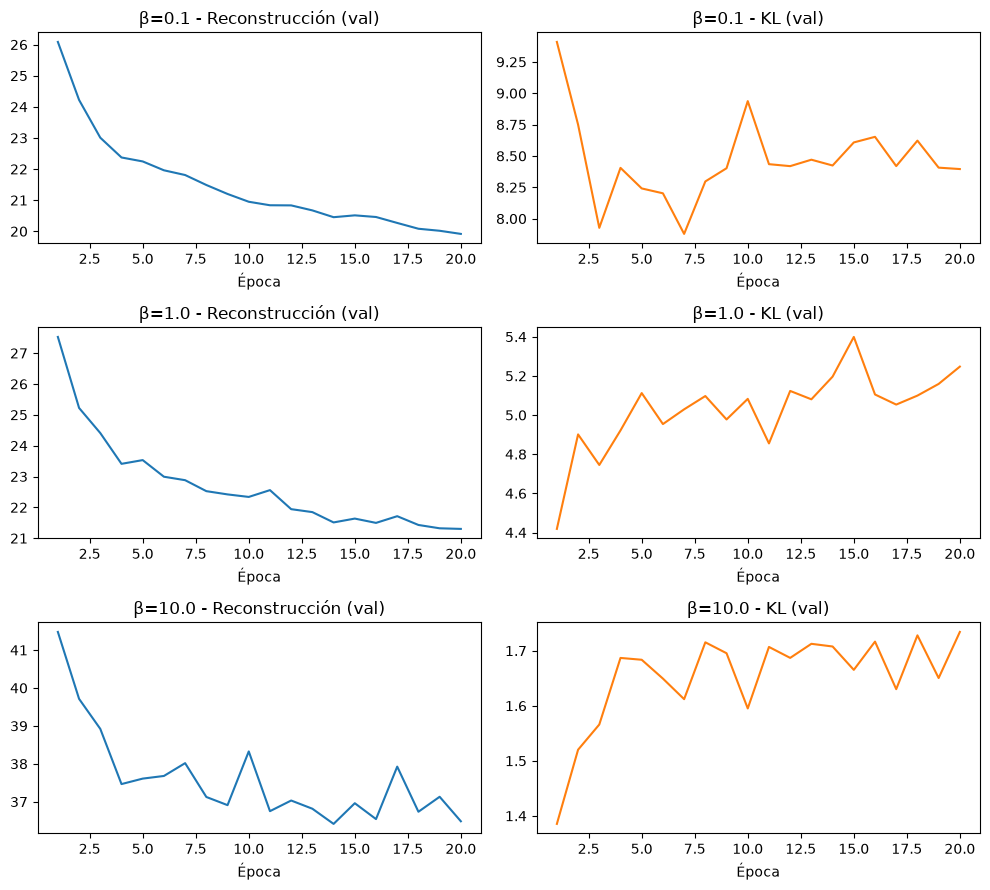

In [2]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(784, 512), nn.ReLU(), nn.Linear(512, 256), nn.ReLU())
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        self.dec = nn.Sequential(nn.Linear(latent_dim, 256), nn.ReLU(), nn.Linear(256, 512), nn.ReLU(),
                                 nn.Linear(512, 784), nn.Sigmoid())

    def encode(self, x):
        h = self.enc(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = reparameterize(mu, logvar)
        return self.dec(z), mu, logvar

# a. Reparametrización z = mu + sigma * eps
def reparameterize(mu, logvar):
    eps = torch.randn_like(mu)
    return mu + torch.exp(0.5 * logvar) * eps

# b. KL en forma cerrada entre N(mu, diag(sigma^2)) y N(0, I), sumada sobre dimensiones latentes
def kl_closed(mu, logvar):
    return 0.5 * torch.sum(mu**2 + torch.exp(logvar) - 1 - logvar, dim=1)

# c. Pérdida por imagen: error cuadrático sumado sobre 784 píxeles + beta * KL
def vae_loss(x, x_hat, mu, logvar, beta):
    recon = torch.sum((x - x_hat) ** 2, dim=1)
    kl = kl_closed(mu, logvar)
    return recon + beta * kl, recon, kl

# Entrenamiento de un modelo por beta
models, history = {}, {}
for beta in beta_values:
    torch.manual_seed(SEED)
    model = VAE(latent_dim).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"val_recon": [], "val_kl": []}
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(x_train.size(0), device=device)
        for i in range(0, x_train.size(0), batch_size):
            xb = x_train[perm[i:i + batch_size]]
            x_hat, mu, logvar = model(xb)
            loss, _, _ = vae_loss(xb, x_hat, mu, logvar, beta)
            opt.zero_grad()
            loss.mean().backward()
            opt.step()
        # Validación por época
        model.eval()
        with torch.no_grad():
            x_hat, mu, logvar = model(x_val)
            _, recon, kl = vae_loss(x_val, x_hat, mu, logvar, beta)
        hist["val_recon"].append(recon.mean().item())
        hist["val_kl"].append(kl.mean().item())
    models[beta], history[beta] = model, hist
    print(f"beta={beta}: recon={hist['val_recon'][-1]:.2f}, KL={hist['val_kl'][-1]:.2f}")

# Curvas de validación por beta
fig, axs = plt.subplots(len(beta_values), 2, figsize=(10, 9))
for r, beta in enumerate(beta_values):
    axs[r, 0].plot(range(1, epochs + 1), history[beta]["val_recon"])
    axs[r, 0].set_title(f"β={beta} - Reconstrucción (val)")
    axs[r, 1].plot(range(1, epochs + 1), history[beta]["val_kl"], color="C1")
    axs[r, 1].set_title(f"β={beta} - KL (val)")
    for a in axs[r]:
        a.set_xlabel("Época")
plt.tight_layout()
plt.show()

### Task 1.3

Con los tres modelos entrenados se generan las figuras solicitadas: (a) dispersión de μ por clase, (b) cuadrícula latente para β = 1, (c) muestras de 𝒩(0, I) por β y (d) interpolaciones en píxeles y en espacio latente para β = 1.

**a.** Dispersión de μ sobre las 5 000 imágenes de validación, por β.

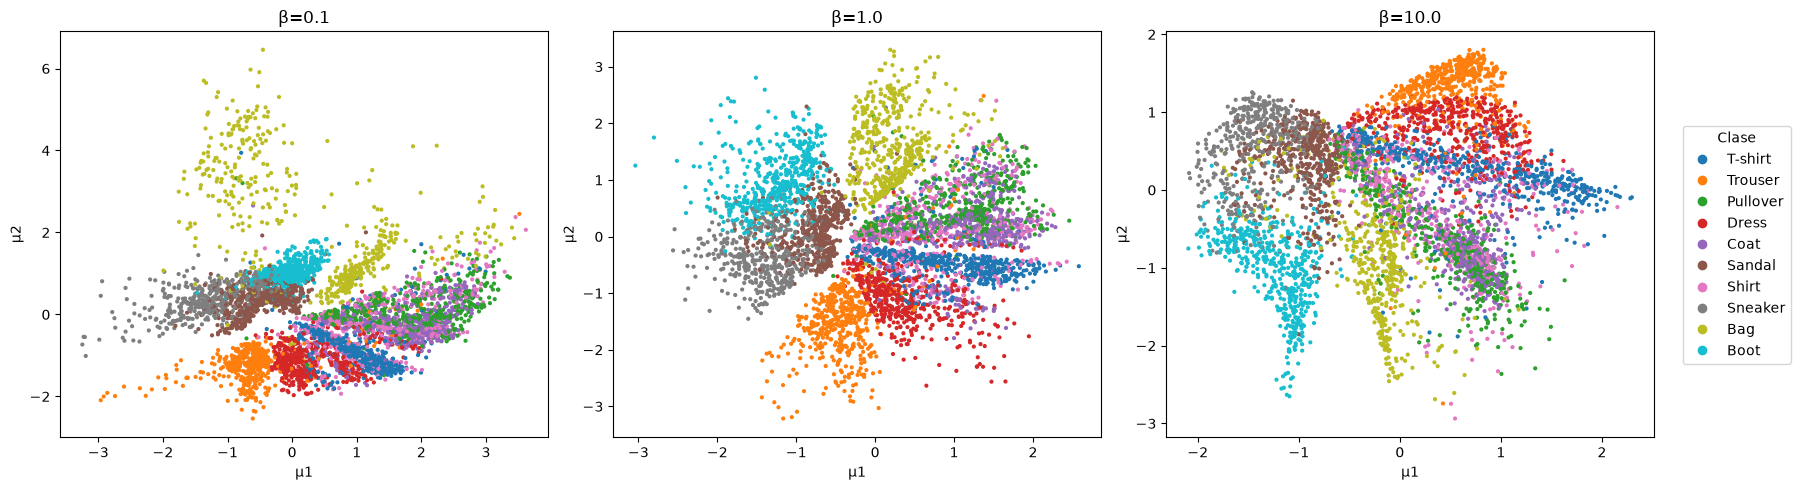

In [3]:
class_names = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Boot"]

# a. Dispersión de mu coloreada por clase (3 paneles)
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
for ax, beta in zip(axs, beta_values):
    models[beta].eval()
    with torch.no_grad():
        mu, _ = models[beta].encode(x_val)
    sc = ax.scatter(mu[:, 0].cpu(), mu[:, 1].cpu(), c=y_val, cmap="tab10", s=4)
    ax.set_title(f"β={beta}")
    ax.set_xlabel("μ1"); ax.set_ylabel("μ2")
handles, _ = sc.legend_elements()
fig.legend(handles, class_names, loc="center right", title="Clase")
plt.tight_layout(rect=[0, 0, 0.93, 1])
plt.show()

**b.** Cuadrícula de 15 × 15 puntos de z en [−3, 3]² decodificada con β = 1.

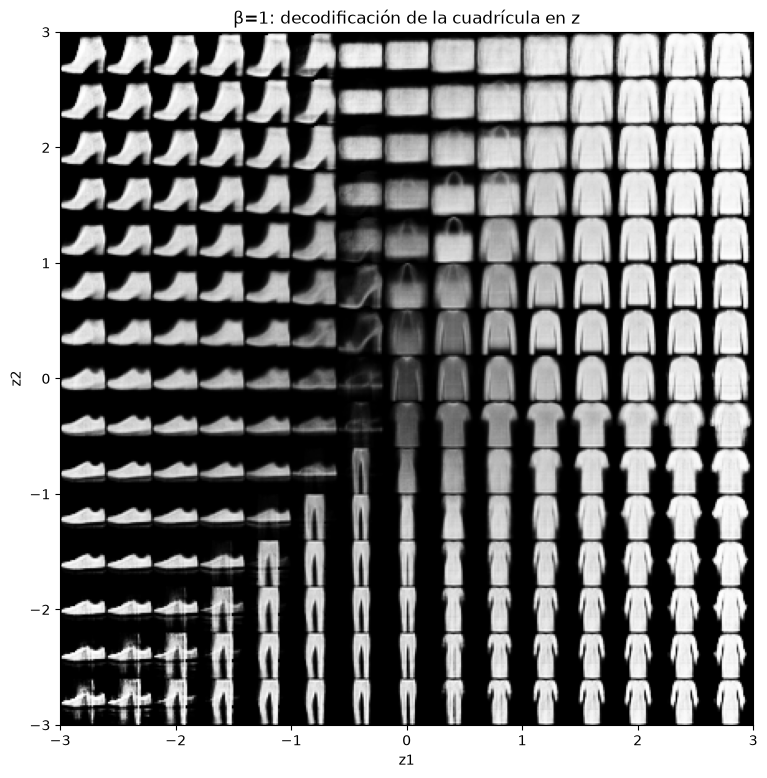

In [4]:
# b. Cuadrícula regular 15x15 en [-3,3]^2 (beta = 1)
n = 15
g = torch.linspace(-3, 3, n)
zy, zx = torch.meshgrid(torch.flip(g, [0]), g, indexing="ij")
z_grid = torch.stack([zx.reshape(-1), zy.reshape(-1)], dim=1).to(device)
with torch.no_grad():
    imgs = models[1.0].dec(z_grid).view(n, n, 28, 28).cpu()
canvas = imgs.permute(0, 2, 1, 3).reshape(n * 28, n * 28)
plt.figure(figsize=(9, 9))
plt.imshow(canvas, cmap="gray", extent=[-3, 3, -3, 3])
plt.xlabel("z1"); plt.ylabel("z2"); plt.title("β=1: decodificación de la cuadrícula en z")
plt.show()

**c.** 64 imágenes generadas con z ~ 𝒩(0, I) para cada β.

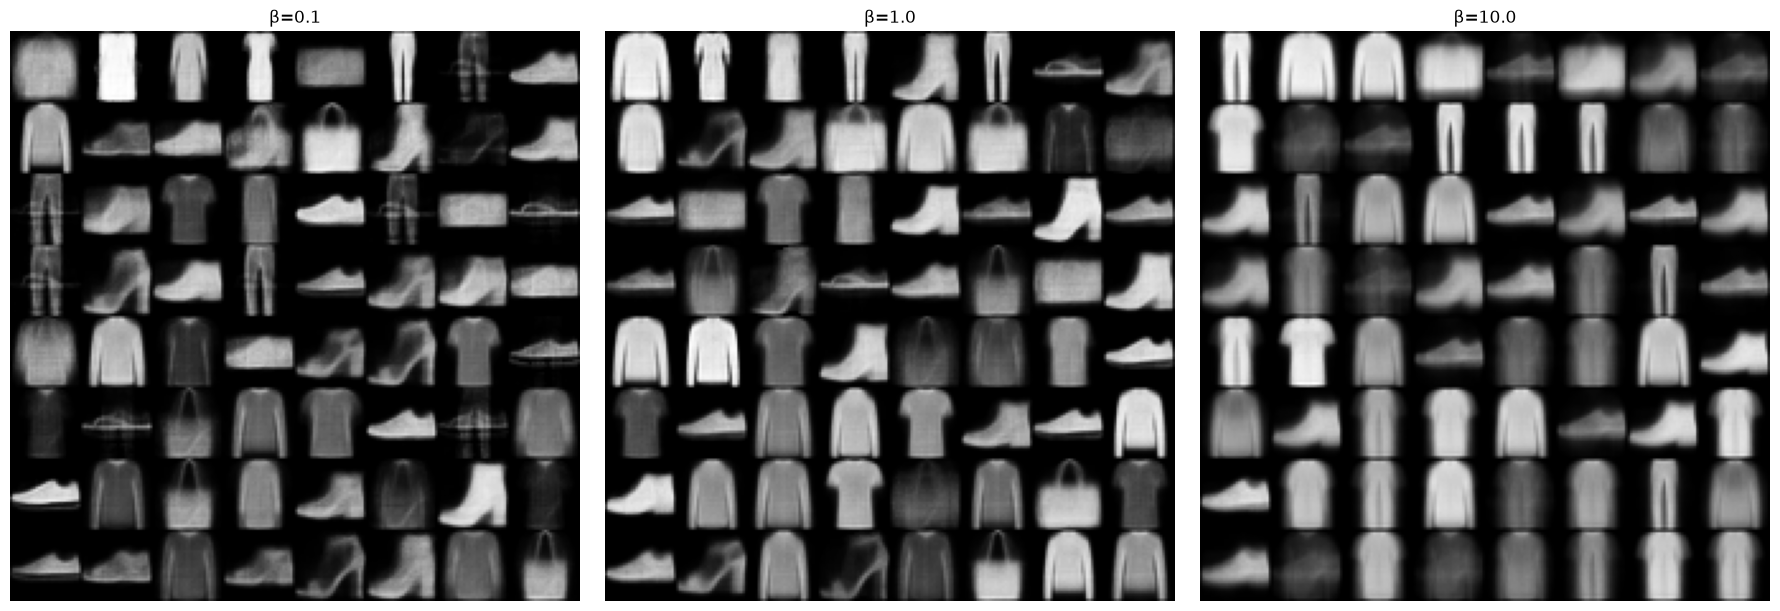

In [5]:
# c. 64 muestras generadas con z ~ N(0, I) por beta
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
for ax, beta in zip(axs, beta_values):
    torch.manual_seed(SEED)
    z = torch.randn(64, latent_dim, device=device)
    with torch.no_grad():
        s = models[beta].dec(z).view(8, 8, 28, 28).cpu()
    ax.imshow(s.permute(0, 2, 1, 3).reshape(8 * 28, 8 * 28), cmap="gray")
    ax.set_title(f"β={beta}"); ax.axis("off")
plt.tight_layout()
plt.show()

**d.** Interpolación entre dos imágenes de validación de clases distintas (8 puntos intermedios) en píxeles y en espacio latente, con β = 1.

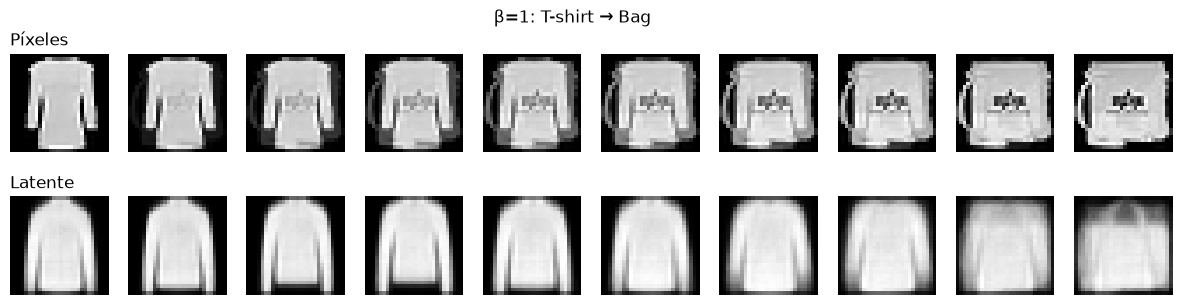

In [6]:
# d. Interpolación entre dos imágenes de clases distintas (beta = 1)
ia = 0
ib = int((y_val != y_val[ia]).nonzero()[0])
xa, xb = x_val[ia:ia + 1], x_val[ib:ib + 1]
alphas = torch.linspace(0, 1, 10, device=device).view(-1, 1)  # extremos + 8 intermedios

# Espacio de píxeles
interp_pix = (1 - alphas) * xa + alphas * xb
# Espacio latente (sobre las medias mu)
with torch.no_grad():
    mu_a, _ = models[1.0].encode(xa)
    mu_b, _ = models[1.0].encode(xb)
    interp_lat = models[1.0].dec((1 - alphas) * mu_a + alphas * mu_b)

fig, axs = plt.subplots(2, 10, figsize=(15, 3.4))
for j in range(10):
    axs[0, j].imshow(interp_pix[j].view(28, 28).cpu(), cmap="gray")
    axs[1, j].imshow(interp_lat[j].view(28, 28).cpu(), cmap="gray")
    axs[0, j].axis("off"); axs[1, j].axis("off")
axs[0, 0].set_title("Píxeles", loc="left"); axs[1, 0].set_title("Latente", loc="left")
plt.suptitle(f"β=1: {class_names[int(y_val[ia])]} → {class_names[int(y_val[ib])]}")
plt.show()

### Task 1.4

Se calculan los valores numéricos que sustentan el análisis: tabla de reconstrucción y KL (en nats y bits), verificación Monte Carlo de la KL, puntos medios de las interpolaciones y nitidez de imágenes reales y generadas. Las respuestas a las preguntas se encuentran en el documento adjunto.

**a.** Tabla de reconstrucción y KL de validación finales por β.

In [7]:
# a. Tabla final: reconstrucción, KL (nats y bits) y referencia log2(10)
tabla = pd.DataFrame({
    "beta": beta_values,
    "Reconstrucción": [history[b]["val_recon"][-1] for b in beta_values],
    "KL (nats)": [history[b]["val_kl"][-1] for b in beta_values],
})
tabla["KL (bits)"] = tabla["KL (nats)"] / math.log(2)
print(tabla.round(3).to_string(index=False))
print("log2(10) =", round(math.log2(10), 3), "bits")

 beta  Reconstrucción  KL (nats)  KL (bits)
  0.1          19.916      8.396     12.112
  1.0          21.302      5.248      7.571
 10.0          36.484      1.734      2.502
log2(10) = 3.322 bits


**b.** Verificación de la KL en forma cerrada contra una estimación Monte Carlo (10⁵ muestras), β = 1.

In [8]:
# b. KL cerrada vs Monte Carlo para una imagen de validación (beta = 1)
x0 = x_val[0:1]
with torch.no_grad():
    mu, logvar = models[1.0].encode(x0)
    kl_exact = kl_closed(mu, logvar).item()

N = 10**5
sigma = torch.exp(0.5 * logvar)
z = mu + sigma * torch.randn(N, latent_dim, device=device)
log_q = (-0.5 * (math.log(2 * math.pi) + logvar + (z - mu) ** 2 / sigma**2)).sum(1)
log_p = (-0.5 * (math.log(2 * math.pi) + z**2)).sum(1)
diff = log_q - log_p
kl_mc = diff.mean().item()
se = (diff.std() / math.sqrt(N)).item()  # error estándar de la estimación MC

print("mu:", mu.cpu().numpy(), "sigma:", sigma.cpu().numpy())
print(f"KL cerrada = {kl_exact:.5f} | KL Monte Carlo = {kl_mc:.5f}")
print(f"Error relativo = {abs(kl_mc - kl_exact) / kl_exact:.2e} | Error estándar MC = {se:.5f}")

mu: [[1.9572161  0.11469858]] sigma: [[0.15144756 0.0818752 ]]
KL cerrada = 5.32682 | KL Monte Carlo = 5.31888
Error relativo = 1.49e-03 | Error estándar MC = 0.00329


**c.** Puntos medios (α = 0.5) de la interpolación en píxeles y en espacio latente, junto con la norma de z en esos puntos.

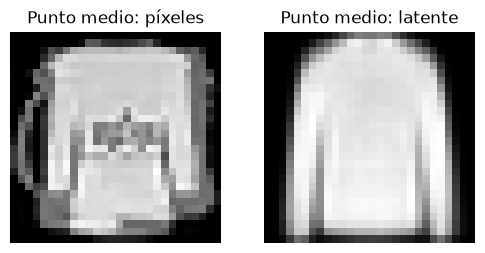

||mu_a|| = 1.9605740308761597 | ||mu_b|| = 2.310948610305786 | ||z_medio|| = 1.8328295946121216


In [9]:
# c. Punto medio de cada interpolación (beta = 1), usando el par de imágenes de 1.3 d
with torch.no_grad():
    z_mid = 0.5 * (mu_a + mu_b)
    mid_lat = models[1.0].dec(z_mid)
mid_pix = 0.5 * (xa + xb)

fig, axs = plt.subplots(1, 2, figsize=(6, 3))
axs[0].imshow(mid_pix.view(28, 28).cpu(), cmap="gray"); axs[0].set_title("Punto medio: píxeles")
axs[1].imshow(mid_lat.view(28, 28).cpu(), cmap="gray"); axs[1].set_title("Punto medio: latente")
for a in axs: a.axis("off")
plt.show()
print("||mu_a|| =", mu_a.norm().item(), "| ||mu_b|| =", mu_b.norm().item(), "| ||z_medio|| =", z_mid.norm().item())

**d.** Nitidez (magnitud media de la diferencia entre píxeles horizontalmente adyacentes) en 1 000 imágenes reales y 1 000 generadas por cada β.

In [10]:
# d. Nitidez: media de |x[:, j+1] - x[:, j]| entre píxeles horizontalmente adyacentes
def sharpness(imgs):
    imgs = imgs.view(-1, 28, 28)
    return (imgs[:, :, 1:] - imgs[:, :, :-1]).abs().mean().item()

res = {"Real": sharpness(x_val[:1000])}
for beta in beta_values:
    torch.manual_seed(SEED)
    with torch.no_grad():
        gen = models[beta].dec(torch.randn(1000, latent_dim, device=device))
    res[f"VAE β={beta}"] = sharpness(gen)
print(pd.Series(res, name="Nitidez").round(4).to_string())

Real          0.0891
VAE β=0.1     0.0434
VAE β=1.0     0.0482
VAE β=10.0    0.0452
